# Analyse BRS Event Data

In [1]:
import os
import yaml
import numpy as np
import matplotlib.pyplot as plt

from sixdegrees import sixdegrees

## Configurations

Load configuration file

This can be prepared using the *brs_make_config.ipynb* notebook

In [39]:
# event = "2024_06_28"
# event = "2024_04_03"
event = "2025_07_29"

# get config from yaml file
config = sixdegrees.load_from_yaml(f"./config/{event}")


Create directory for plotting outputs

In [40]:
# create a folder for the project figures
if not os.path.exists(f"./figures/{config['project']}"):
    os.makedirs(f"./figures/{config['project']}")

# update the path to the figures
config['path_to_figures'] = f"./figures/{config['project']}/"

Setup a sixdegrees instance

In [41]:
sd = sixdegrees(conf=config)

Get key information about the event

In [74]:
ev = sd.get_event_info(
    origin_time=config['origin_time'],
    base_catalog="USGS",
    magnitude=config['magnitude'],
    time_margin=1000
)

Error getting event information from USGS:
No FDSN services could be discovered at 'http://earthquake.usgs.gov'. This could be due to a temporary service outage or an invalid FDSN service address.
No event found in USGS catalog for given time. Using dummy event info.


In [75]:
# manually set event information (if not obtained from client)
ev = {
    'latitude': 52.55,
    'longitude': 160.10,
    'depth_km': 21,
    'magnitude': 8.8,
}

#compute backazimuth and distance
from obspy.geodetics import gps2dist_azimuth

dist, az, baz = gps2dist_azimuth(ev['latitude'], ev['longitude'], config['station_lat'], config['station_lon'])

ev['distance_km'] = dist / 1000
ev['backazimuth'] = baz

This will load the data from the data source:
- local mseed file
- local sds system
- fdsn (online)

and trim it to the time window

In [45]:
sd.load_data(config['tbeg'], config['tend'], resample_rate=config['resample_rate'])

-> fetching LI.LIV.IX.DHZ data from mseed file
-> fetching LI.LIV.IX.DHX data from mseed file
-> fetching LI.LIV.IX.DHY data from mseed file
-> translation inventory provided: metadata/station_LI_LIV.xml
-> removing response: VEL
3 Trace(s) in Stream:
LI.LIV.IX.DHZ | 2024-04-03T00:14:59.000000Z - 2024-04-03T01:45:01.000000Z | 512.0 Hz, 2765825 samples
LI.LIV.IX.DHX | 2024-04-03T00:14:59.000000Z - 2024-04-03T01:45:01.000000Z | 512.0 Hz, 2765825 samples
LI.LIV.IX.DHY | 2024-04-03T00:14:59.000000Z - 2024-04-03T01:45:01.000000Z | 512.0 Hz, 2765825 samples
-> fetching LI.LIV.IY.DJX data from mseed file
-> fetching LI.LIV.IX.DJY data from mseed file
-> adding dummy trace: LI.LIV.IX.DJZ
-> rotation inventory provided: metadata/station_LI_LIV.xml
3 Trace(s) in Stream:
LI.LIV.IY.DJX | 2024-04-03T00:14:59.000000Z - 2024-04-03T01:45:01.000000Z | 256.0 Hz, 1382913 samples
LI.LIV.IX.DJY | 2024-04-03T00:14:59.000000Z - 2024-04-03T01:45:01.000000Z | 256.0 Hz, 1382913 samples
LI.LIV.IX.DJZ | 2024-04-0

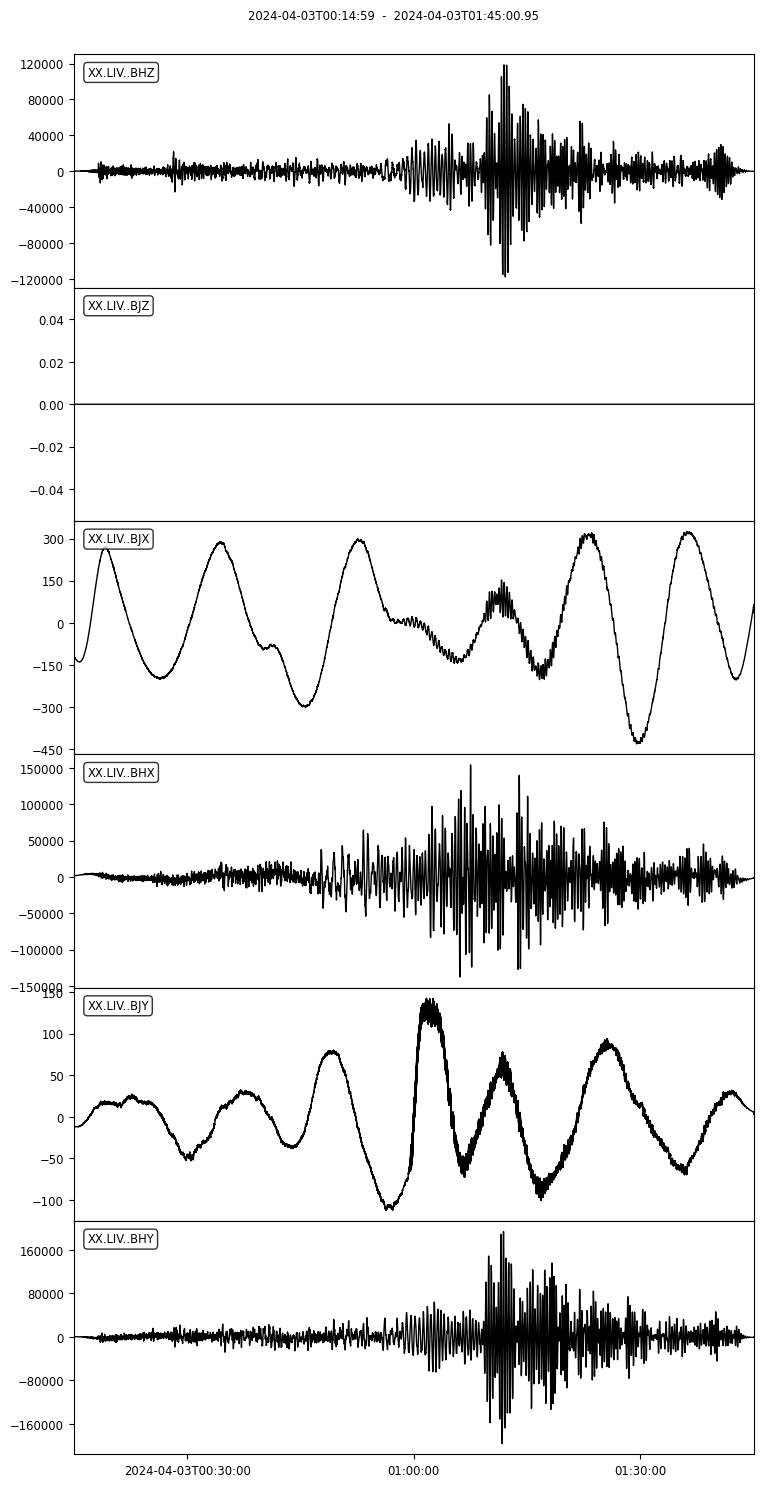

In [46]:
sd.st.plot(equal_scale=False);

Ensure that all traces of stream have the same sample size

In [47]:
sd.trim_stream(set_common=True, set_interpolate=False)

### Rotate data to ZNE

In [48]:
# seems to work better for tangent method if the components are inverted (not clear why yet)
sd.st.select(station="LIV", channel="*JX")[0].data *= -1
sd.st.select(station="LIV", channel="*JY")[0].data *= -1


In [49]:
from obspy.signal.rotate import rotate2zne

# as in file
IX = 162.2835
IY = 252.2835

code = "B"

Z, N, E = rotated_data = rotate2zne(
    sd.st.select(station="LIV", channel="*JZ")[0].data, 0, 90,
    sd.st.select(station="LIV", channel="*JX")[0].data, IY, 0,
    sd.st.select(station="LIV", channel="*JY")[0].data, IX, 0,
)
sd.st.select(station="LIV", channel="*JX")[0].data = E
sd.st.select(station="LIV", channel="*JX")[0].stats.channel = code+"JE"

sd.st.select(station="LIV", channel="*JY")[0].data = N
sd.st.select(station="LIV", channel="*JY")[0].stats.channel = code+"JN"

Z, N, E = rotated_data = rotate2zne(
    sd.st.select(station="LIV", channel="*HZ")[0].data, 0, -90,
    sd.st.select(station="LIV", channel="*HY")[0].data, IY, 0,
    sd.st.select(station="LIV", channel="*HX")[0].data, IX, 0,
)
sd.st.select(station="LIV", channel="*HX")[0].data = E
sd.st.select(station="LIV", channel="*HX")[0].stats.channel = code+"HE"

sd.st.select(station="LIV", channel="*HY")[0].data = N
sd.st.select(station="LIV", channel="*HY")[0].stats.channel = code+"HN"


In [50]:
# correct amplitudes from paul which has it in nanorad and nanometer/s

for tr in sd.st:
    if "H" in tr.stats.channel[1]:
        tr.data = tr.data / 1e9 
    elif "J" in tr.stats.channel[1]:
        tr.data = tr.data / 1e9


### Wavelet Comparsion

In [51]:
# # First compute CWT for all components
# cwt_results = {}
# for comp in ['Z', 'N', 'E']:

#     try:
#         # Rotation components
#         rot_data = sd.get_stream("rotation").select(channel=f"*{comp}")[0]
#         cwt_results[f"{comp}_Rotation"] = sd.compute_cwt(
#             rot_data.times(), rot_data.data, rot_data.stats.delta,
#             normalize=True
#         )

#         del rot_data
#     except:
#         print(f"No {comp} data for rotation")
#     try:
#         # Translation components
#         acc_data = sd.get_stream("translation").select(channel=f"*{comp}")[0]
#         cwt_results[f"{comp}_Translation"] = sd.compute_cwt(
#             acc_data.times(), acc_data.data, acc_data.stats.delta,
#             normalize=True
#         )

#         del acc_data
#     except:
#         print(f"No {comp} data for translation")


In [52]:
# # Then plot all components
# fig = sixdegrees.plot_cwt_all(
#     rot=sd.get_stream("rotation"),
#     acc=sd.get_stream("translation"),
#     cwt_output=cwt_results,
#     clog=True,
#     ylim=1
# )

## Analysis

In [53]:
# Parameters to use for the analysis

# frequency band
fmin, fmax = 0.01, 0.1

# window factor
t_win_factor = 8

# overlap
Toverlap = 0.75

# cross-correlation threshold
cc_threshold = 0.8


In [54]:
# center frequency
fcenter = np.round(np.sqrt(fmax*fmin), 2)

# compute time window
Twindow = t_win_factor * int(1/fcenter)

print("Time window", Twindow, "seconds", "with center frequency", fcenter, "Hz")



Time window 264 seconds with center frequency 0.03 Hz


Frequency band to filter (this is applied to the stream object after being reset to raw stream)

In [55]:
sd.filter_data(fmin=fmin, fmax=fmax, output=False)

Apply polarity correction if needed. This is applied to the stream object that is processed. If raw is True, the polarity correction is applied to the raw stream too.

In [56]:
sd.polarity_stream(pol_dict={"HZ": -1, "JZ": 1}, raw=True)

In [57]:
# sd.st.trim(starttime=sd.tbeg+200, endtime=sd.tend-4000)

Correct horizontal acceleration data

In [58]:
sd.correct_tilt()

In [59]:
# # get cross-correlation function of JT and HZ and find the lag
# from obspy.signal.cross_correlation import correlate, xcorr_max
# from obspy.signal.rotate import rotate_ne_rt

# JN = sd.get_stream("rotation").select(channel="*N")[0].data
# JE = sd.get_stream("rotation").select(channel="*E")[0].data

# JR, JT = rotate_ne_rt(JN, JE, ev['backazimuth'])

# HZ = sd.get_stream("translation").select(channel="*Z")[0].data

# cc0_before = correlate(JT, HZ, 0)

# cc = correlate(JT, HZ, len(JT))

# lag, cc_max = xcorr_max(cc)

# HZ = np.roll(HZ, lag)

# cc0_after = correlate(JT, HZ, 0)

# print(lag, cc_max, cc0_before, cc0_after)

# # sd.st.select(channel="*Z")[0].data = HZ



let's compare the waveforms of the rotation (red) and translational (black) components 

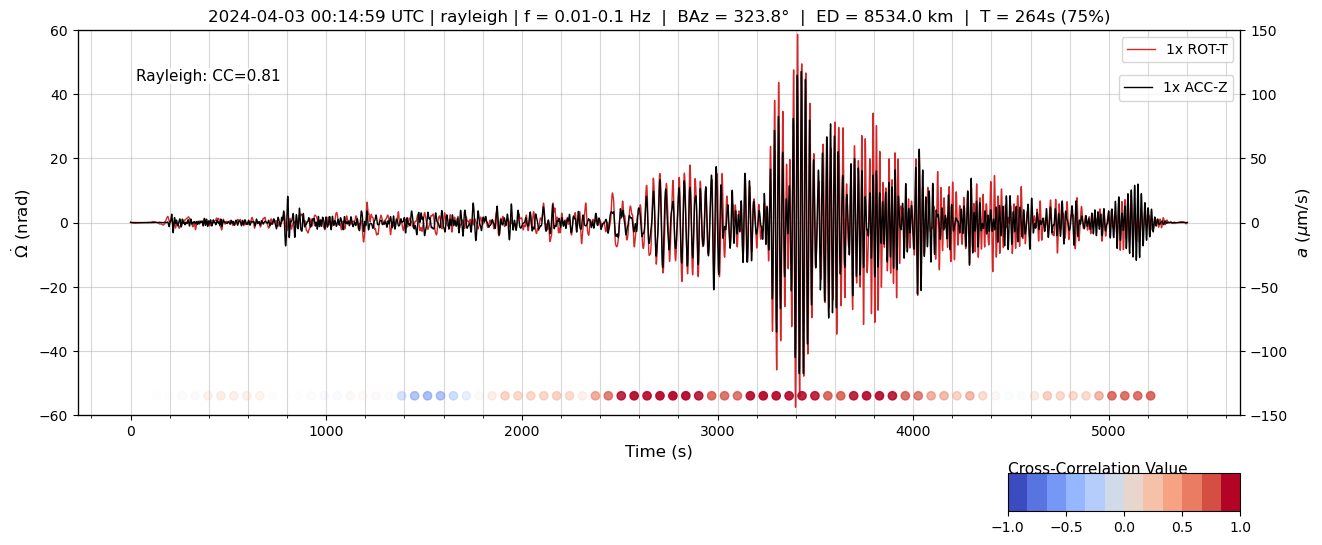

In [60]:
fig = sd.plot_waveform_cc(
    rot0=sd.get_stream("rotation"),
    acc0=sd.get_stream("translation"),
    baz=ev['backazimuth'],
    distance=ev['distance_km'],
    fmin=fmin,
    fmax=fmax,
    twin_sec=Twindow,
    twin_overlap=Toverlap,
    wave_type="rayleigh",
    runit=config['runit'],
    tunit=config['tunit']
)

fig.savefig(f"{config['path_to_figures']}{config['project']}_waveform_cc.png", bbox_inches='tight')


In [24]:
# fig = sd.plot_spectra_comparison_fill(rot=sd.get_stream("rotation"), 
#                                       acc=sd.get_stream("translation"),
#                                       fmin=0.09, fmax=0.6,
#                                       ylog=False, xlog=False, fill=True
#                                       )

### Backazimuth Estimate

In [61]:
# compute backazimuth
baz_results = sd.compute_backazimuth(
    wave_type='rayleigh',
    baz_step=1,
    baz_win_sec=Twindow,
    baz_win_overlap=Toverlap,
    out=True
)


baz_max = 17, baz_std = 38


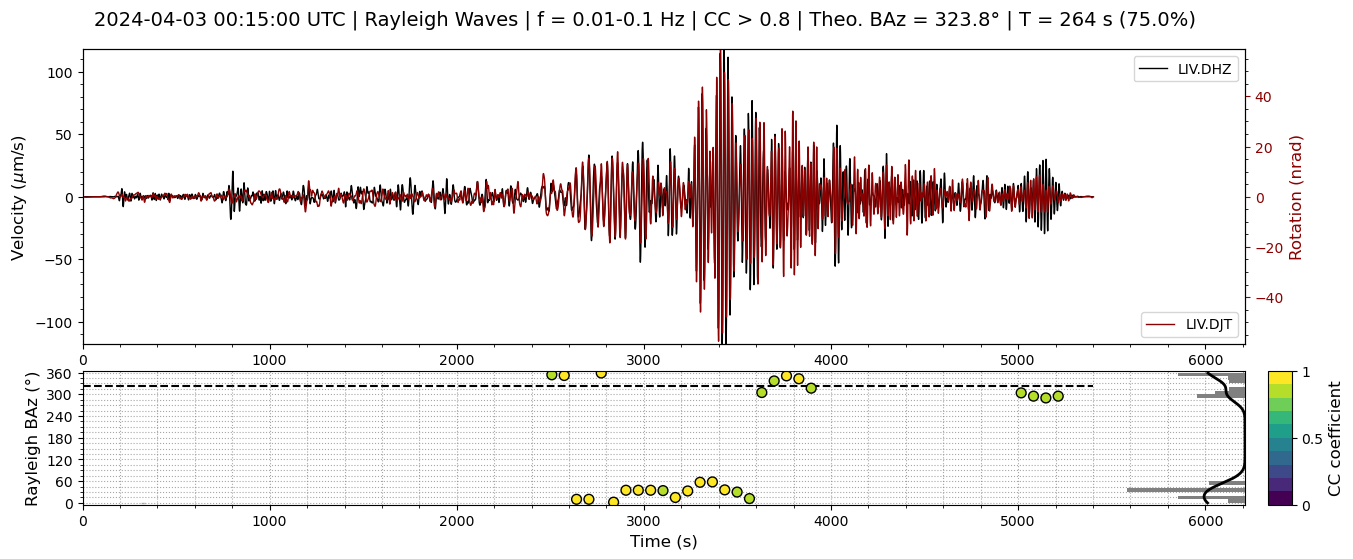

In [62]:
fig = sd.plot_backazimuth_results(
    baz_results,
    wave_type='rayleigh',
    baz_theo=ev['backazimuth'],
    cc_threshold=cc_threshold,  # optional
    cc_value='max',
    unitscale='nano' # for rotation rate
)

fig.savefig(f"{config['path_to_figures']}{config['project']}_backazimuth_max.png", bbox_inches='tight')

baz_max = 352, baz_std = 13


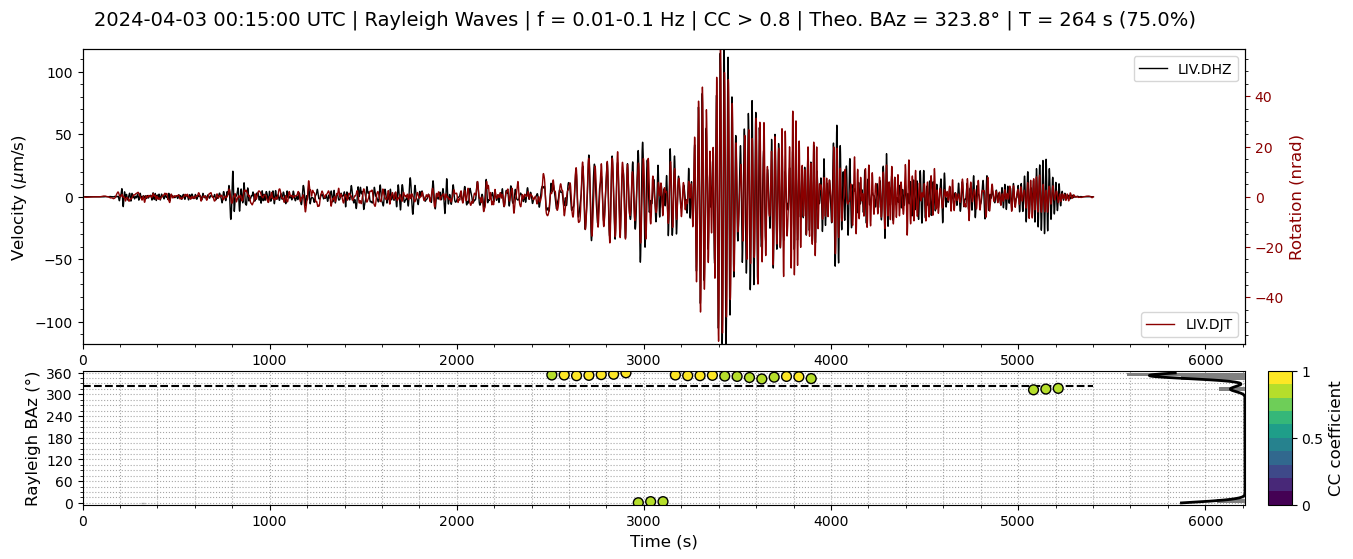

In [63]:
fig = sd.plot_backazimuth_results(
    baz_results,
    wave_type='rayleigh',
    baz_theo=ev['backazimuth'],
    cc_threshold=cc_threshold,  # optional
    cc_value='mid',
    unitscale='nano' # for rotation rate
)

fig.savefig(f"{config['path_to_figures']}{config['project']}_backazimuth_mid.png", bbox_inches='tight')

### Estimate Phase Velocities

In [64]:
# estimate phase velocities
results_vel1 = sd.compute_velocities(
    wave_type='rayleigh',
    win_time_s=Twindow,
    overlap=Toverlap,
    baz=ev['backazimuth'],
    method="ransac"

)

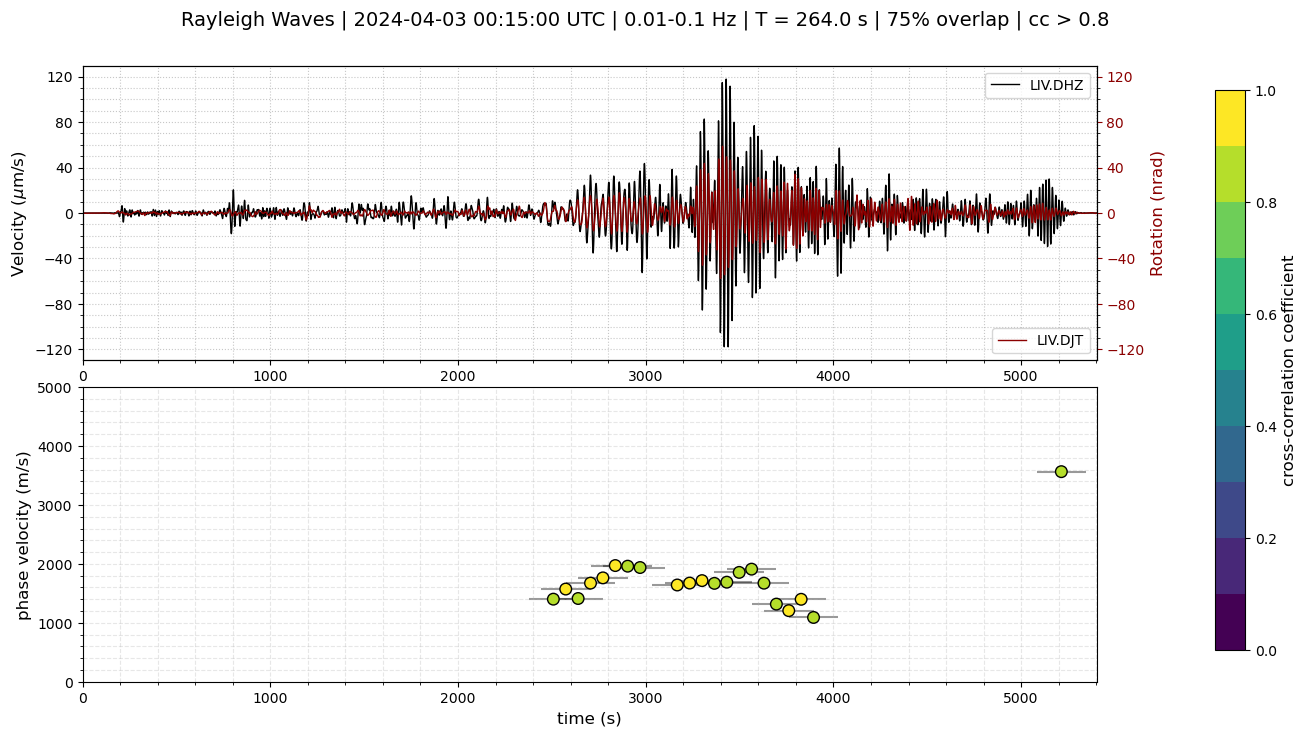

In [65]:
fig = sd.plot_velocities(
    results_vel1,
    cc_threshold=cc_threshold,
    vmax=5000
);

fig.savefig(f"{config['path_to_figures']}{config['project']}_velocities.png", bbox_inches='tight')

Compute phase velocity estimates based on an optimized approach wich the estimated backazimuth for rotation for each time window instead of the expected backazimuth

In [66]:
results_vel_adaptive = sd.compute_velocities_optimized(
    rotation_data=sd.get_stream("rotation", raw=False),
    translation_data=sd.get_stream("translation", raw=False),
    wave_type='rayleigh',
    baz_results=baz_results,
    baz_mode="mid",
    method="ransac",
    cc_threshold=0.5
)

results_vel_adaptive['parameters']['baz'] = ev['backazimuth']
results_vel_adaptive['ccoef'] = results_vel_adaptive['cc_value']
results_vel_adaptive['time'] = results_vel_adaptive['times']
results_vel_adaptive['terr'] = np.ones(len(results_vel_adaptive['time']))*Twindow/2


78it [00:00, 274.37it/s]


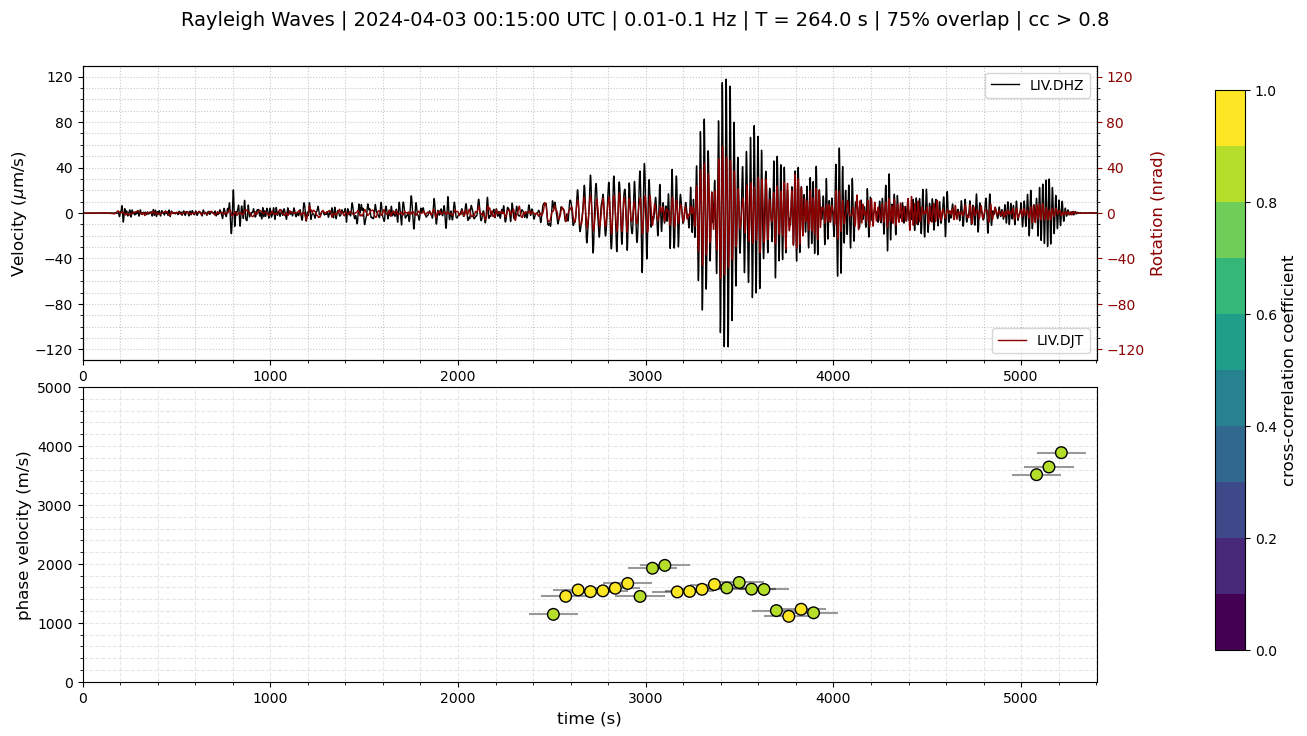

In [67]:
fig = sd.plot_velocities(
    results_vel_adaptive, 
    cc_threshold=cc_threshold,
    vmax=5000
)

fig.savefig(f"{config['path_to_figures']}{config['project']}_velocities_adaptive.png", bbox_inches='tight')

In [68]:
from utils import plot_velocity_comparison

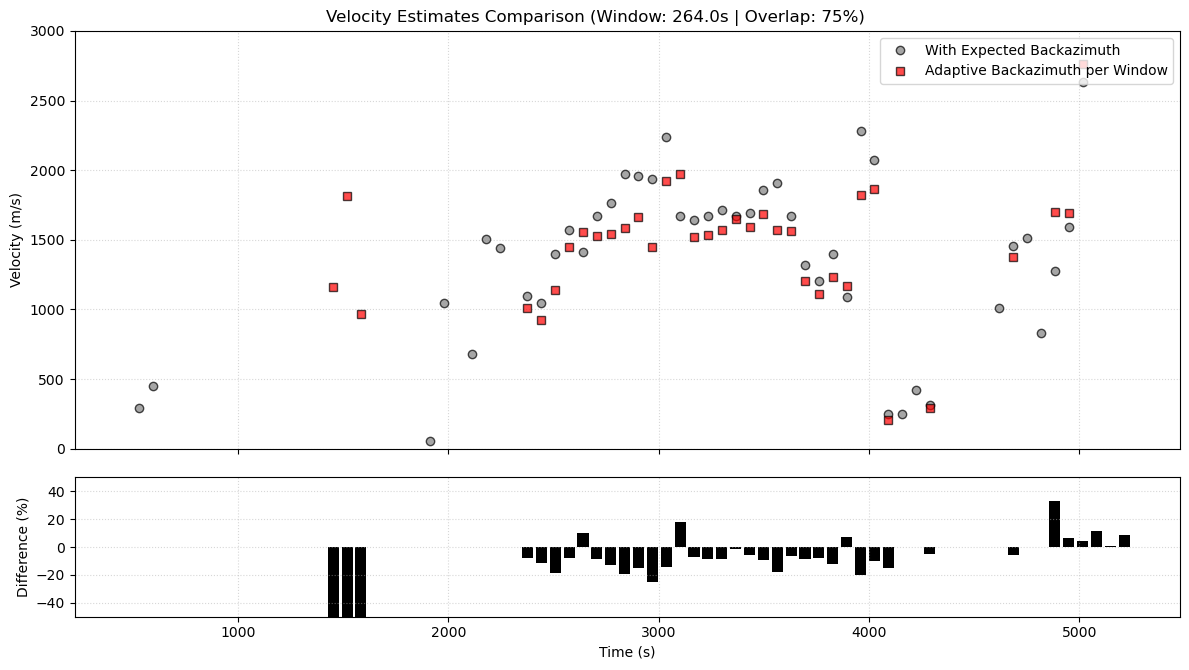

In [69]:
fig = plot_velocity_comparison(
    results_vel1, results_vel_adaptive,
    labels=('With Expected Backazimuth', 'Adaptive Backazimuth per Window'),
    title='Velocity Estimates Comparison'
)

fig.savefig(f"{config['path_to_figures']}{config['project']}_velocities_comparison.png", bbox_inches='tight')

### Plot Backazimuth Estimates on a Map

In [70]:
from utils import plot_backazimuth_map

In [71]:
results_map = sd.compute_backazimuth_map(
    wave_types=['rayleigh','tangent'],
    cc_threshold=cc_threshold,
    baz_win_sec=Twindow,
    baz_win_overlap=Toverlap,
)

Using precomputed rayleigh backazimuth results
Computing tangent backazimuth with rotation components...


#### Plot the Backazimuth Estimates on a Map

ERROR plotting theoretical great circle: Format specifier missing precision


/home/andbro/cursorfiles/BRS/utils.py:2346: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


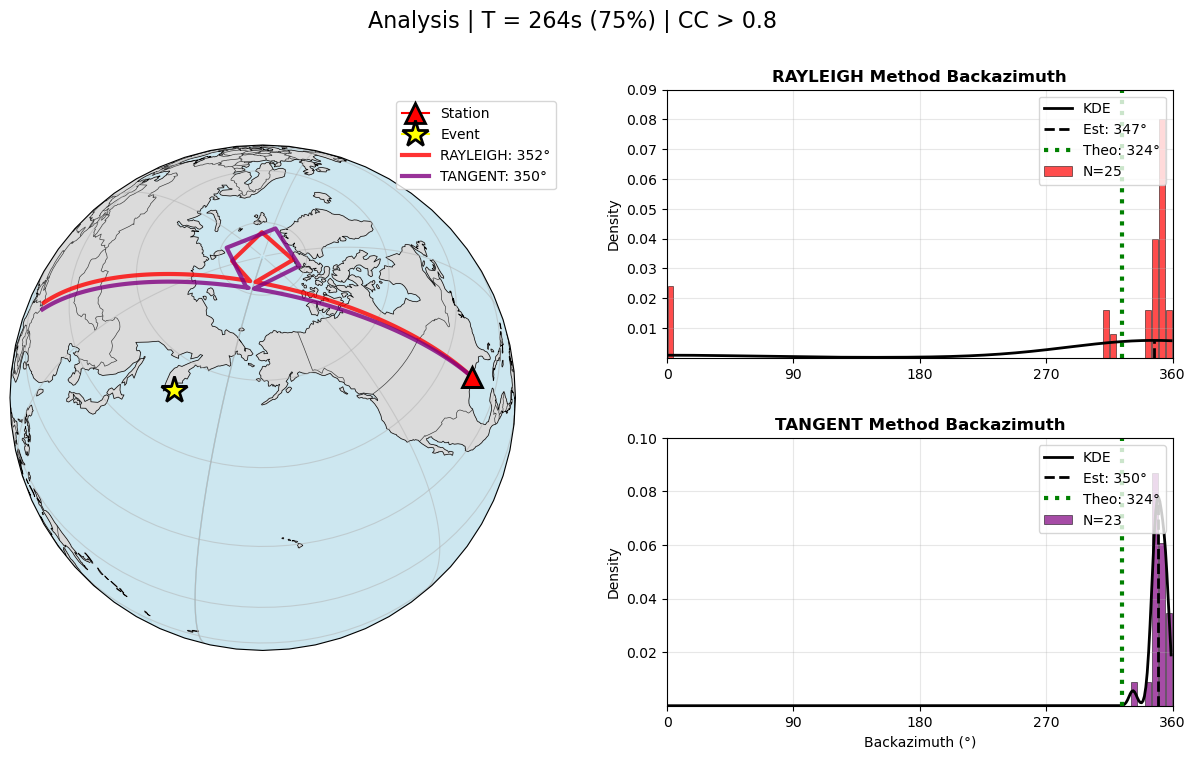

In [72]:
fig = plot_backazimuth_map(
    results_map,
    event_info=ev,
    map_projection='orthographic',  # 'orthographic' or 'platecarree'
    debug=False,
)

fig.savefig(f"{config['path_to_figures']}{config['project']}_backazimuth_map.png", bbox_inches='tight')

### Compute Velocity and Backazimuth with Frequency

Using ocatve bands to filter the data and then estimate the backazimuth and velocities

In [36]:
results_freq = sd.compute_frequency_dependent_parameters_parallel(
    wave_type='rayleigh',
    fbands={'fmin': 0.01, 'fmax': 0.5, 'octave_fraction': 3},
    t_win_factor=t_win_factor,
    overlap=Toverlap,
    baz_mode='mid',
    method='ransac',
    cc_threshold=cc_threshold,
    n_jobs=3
)

Processing 18 frequency bands using 3 processes...


Processing frequency bands:   6%|▌         | 1/18 [00:44<12:40, 44.76s/band]

✓ Processed 0.010 Hz (T=800.0s)


42it [00:00, 404.25it/s]
Processing frequency bands:  11%|█         | 2/18 [00:55<06:31, 24.47s/band]

✓ Processed 0.013 Hz (T=635.0s)


54it [00:00, 352.40it/s]
Processing frequency bands:  17%|█▋        | 3/18 [01:06<04:40, 18.69s/band]

... (27 outputs left out)

1437it [00:00, 1439.52it/s]
Processing frequency bands:  94%|█████████▍| 17/18 [36:07<04:20, 260.41s/band]

✓ Processed 0.398 Hz (T=20.0s)


1917it [00:01, 1614.05it/s]
Processing frequency bands: 100%|██████████| 18/18 [40:09<00:00, 133.89s/band]

✓ Processed 0.501 Hz (T=15.0s)
Completed processing 18 frequency bands successfully.


In [37]:
def plot_frequency_dependent(results_freq, data='vel', figsize=(12, 5), minors=True, fmin=None, fmax=None) -> plt.Figure:
    """
    Plot frequency-dependent velocity results with scatter points and connecting lines.
    
    Parameters
    ----------
    results_freq : Dict
        Results dictionary from compute_frequency_dependent_parameters
    data : str, optional
        Data to plot vel or baz, by default 'vel'
    figsize : Tuple[int, int], optional
        Figure size (width, height), by default (10, 6)
    minors : bool, optional
        Add minor ticks to axes if Tr   ue, by default True
    fmin : float, optional
        Minimum frequency to plot, by default None
    fmax : float, optional
        Maximum frequency to plot, by default None
        
    Returns
    -------
    matplotlib.figure.Figure
        The generated figure
    """
    import numpy as np
    import matplotlib.pyplot as plt
    
    # Create figure
    fig, ax = plt.subplots(figsize=figsize)
    
    # Get data
    frequencies = np.array(results_freq['frequency'])
    velocities = np.array(results_freq['velocity'])
    cc_values = np.array(results_freq['cc_values'])
    backazimuths = np.array(results_freq['backazimuth'])

    # Sort by frequency to ensure line plot connects points in order
    sort_idx = np.argsort(frequencies)
    frequencies = frequencies[sort_idx]
    velocities = velocities[sort_idx]
    cc_values = cc_values[sort_idx]
    backazimuths = backazimuths[sort_idx]

    # Create scatter plot with colorbar for CC values
    if data == 'vel':
        scatter = ax.scatter(frequencies, velocities, c=cc_values, 
                            cmap='viridis', s=100, alpha=1,
                            edgecolor='black', linewidth=1, zorder=5,
                            vmax=1, vmin=0.8)
        # Add connecting line
        ax.plot(frequencies, velocities, 'k-', alpha=0.3, zorder=2)

    elif data == 'baz':
        scatter = ax.scatter(frequencies, backazimuths, c=cc_values, 
                            cmap='viridis', s=100, alpha=1,
                            edgecolor='black', linewidth=1, zorder=5,
                            vmax=1, vmin=0.8)
        # Add connecting line
        ax.plot(frequencies, backazimuths, 'k-', alpha=0.3, zorder=2)

    # add error bars for mad
    if data == 'vel':
        try:
            mad = results_freq['vel_mad']
            ax.errorbar(frequencies, velocities, yerr=mad, fmt='none', ecolor='black', alpha=0.3, zorder=4)
        except:
            pass
    elif data == 'baz':
        try:
            mad = results_freq['baz_mad']
            ax.errorbar(frequencies, backazimuths, yerr=mad, fmt='none', ecolor='black', alpha=0.3, zorder=4)

            ax.set_ylim(bottom=0, top=360)
            ax.set_yticks([0, 90, 180, 270, 360])
        except:
            pass

    # Configure axes
    ax.set_xscale('log')
    ax.set_xlabel('Frequency (Hz)', fontsize=12)

    if data == 'vel':
        ax.set_ylabel('Apparent Phase Velocity (m/s)', fontsize=12)
    elif data == 'baz':
        ax.set_ylabel('Backazimuth (°)', fontsize=12)
    
    # Add grid
    ax.grid(True, which='major', alpha=0.3, zorder=1)
    if minors:
        ax.grid(True, which='minor', alpha=0.1, zorder=1)
        ax.minorticks_on()
    
    # Add colorbar
    cbar = plt.colorbar(scatter, pad=0.01, extend='min')
    cbar.set_label('Cross-correlation coefficient', fontsize=12)

    # Set x-axis limits
    if fmin is not None:
        ax.set_xlim(left=fmin)
    if fmax is not None:
        ax.set_xlim(right=fmax)

    # Set y-axis limits based on data type
    if data == 'vel':
        ax.set_ylim(bottom=0)
    if data == 'baz':
        ax.set_ylim(bottom=0, top=360)

    # Add title
    if data == 'vel':
        title = f"{results_freq['parameters']['wave_type'].title()} Wave Velocity vs Frequency "
    elif data == 'baz':
        title = f"{results_freq['parameters']['wave_type'].title()} Wave Backazimuth vs Frequency "
    title += f"(win={results_freq['parameters']['t_win_factor']}/f$_c$, "
    title += f"overlap={results_freq['parameters']['overlap']*100:.0f}%, "
    title += f"method={results_freq['parameters']['method']})"
    ax.set_title(title, fontsize=14)
    
    plt.tight_layout()
    return fig

In [38]:
from utils import plot_frequency_dependent

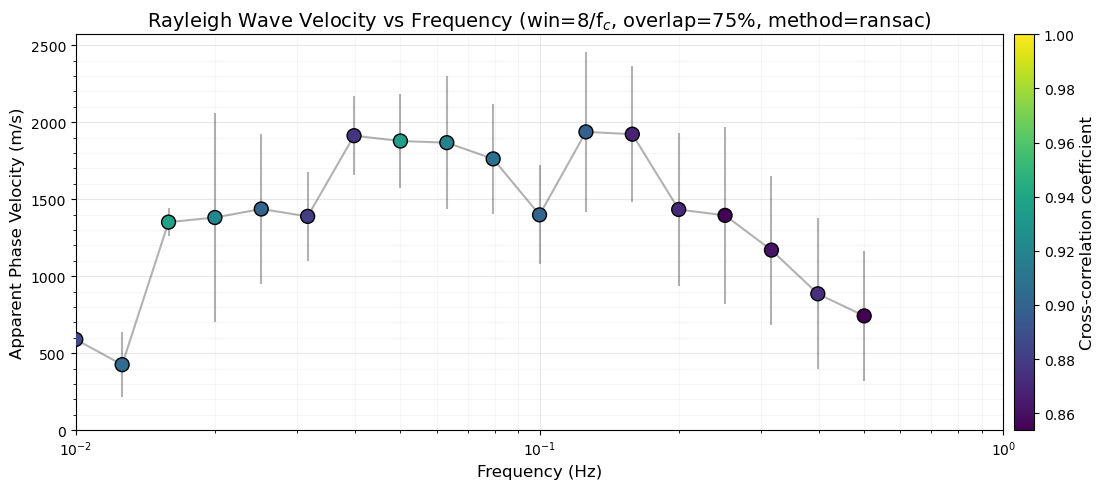

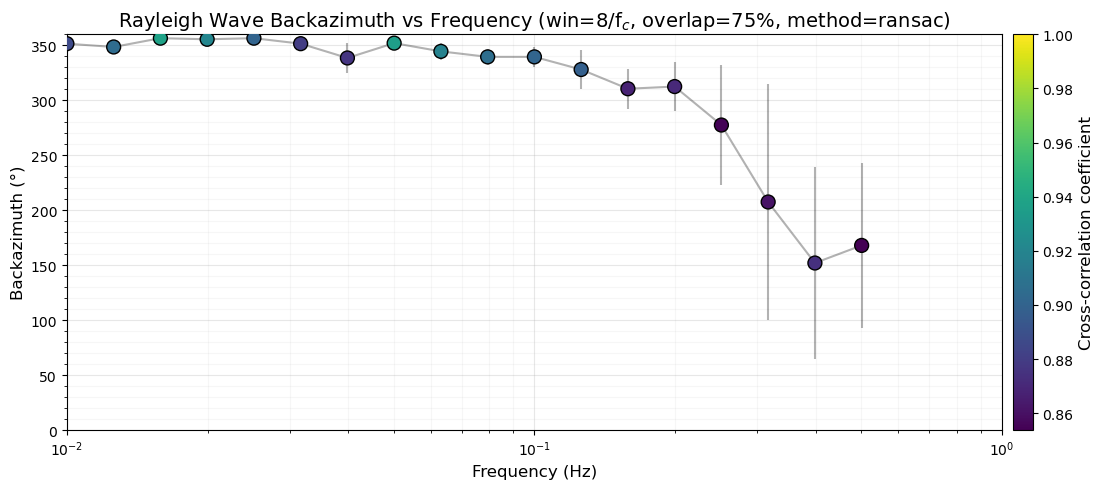

In [39]:
fig = plot_frequency_dependent(results_freq, data='vel', fmin=0.01, fmax=1);

fig.savefig(f"{config['path_to_figures']}{config['project']}_frequency_dependent_velocity.png", bbox_inches='tight')


fig = plot_frequency_dependent(results_freq, data='baz', fmin=0.01, fmax=1);

fig.savefig(f"{config['path_to_figures']}{config['project']}_frequency_dependent_backazimuth.png", bbox_inches='tight')


### Animate Waveforms

In [40]:
from utils import animate_waveforms

In [41]:
# Basic usage (displays animation)
animate_waveforms(sd,
                  time_step=10,
                  show_arrivals=True,
                  rotate_zrt=True,
                  baz=ev['backazimuth'],
                  save_path=f"{config['path_to_figures']}{config['project']}_animation.mp4")

Using backazimuth: 323.7746176575145°
3 Trace(s) in Stream:
XX.LIV..BJZ | 2025-07-29T23:29:59.000000Z - 2025-07-30T01:30:00.950000Z | 20.0 Hz, 144040 samples
XX.LIV..BJR | 2025-07-29T23:29:59.000000Z - 2025-07-30T01:30:00.950000Z | 20.0 Hz, 144040 samples
XX.LIV..BJT | 2025-07-29T23:29:59.000000Z - 2025-07-30T01:30:00.950000Z | 20.0 Hz, 144040 samples 3 Trace(s) in Stream:
XX.LIV..BHZ | 2025-07-29T23:29:59.000000Z - 2025-07-30T01:30:00.950000Z | 20.0 Hz, 144040 samples
XX.LIV..BHR | 2025-07-29T23:29:59.000000Z - 2025-07-30T01:30:00.950000Z | 20.0 Hz, 144040 samples
XX.LIV..BJT | 2025-07-29T23:29:59.000000Z - 2025-07-30T01:30:00.950000Z | 20.0 Hz, 144040 samples
Animation parameters:
Duration: 7201.95s
Time step: 10.003s
Number of frames: 720
Frame rate: 0.1 fps
Theoretical P-arrival: 2025-07-29T23:24:50.000000Z
Theoretical S-arrival: 2025-07-29T23:24:50.000000Z
